Всего доступно размеченных кадров: 568


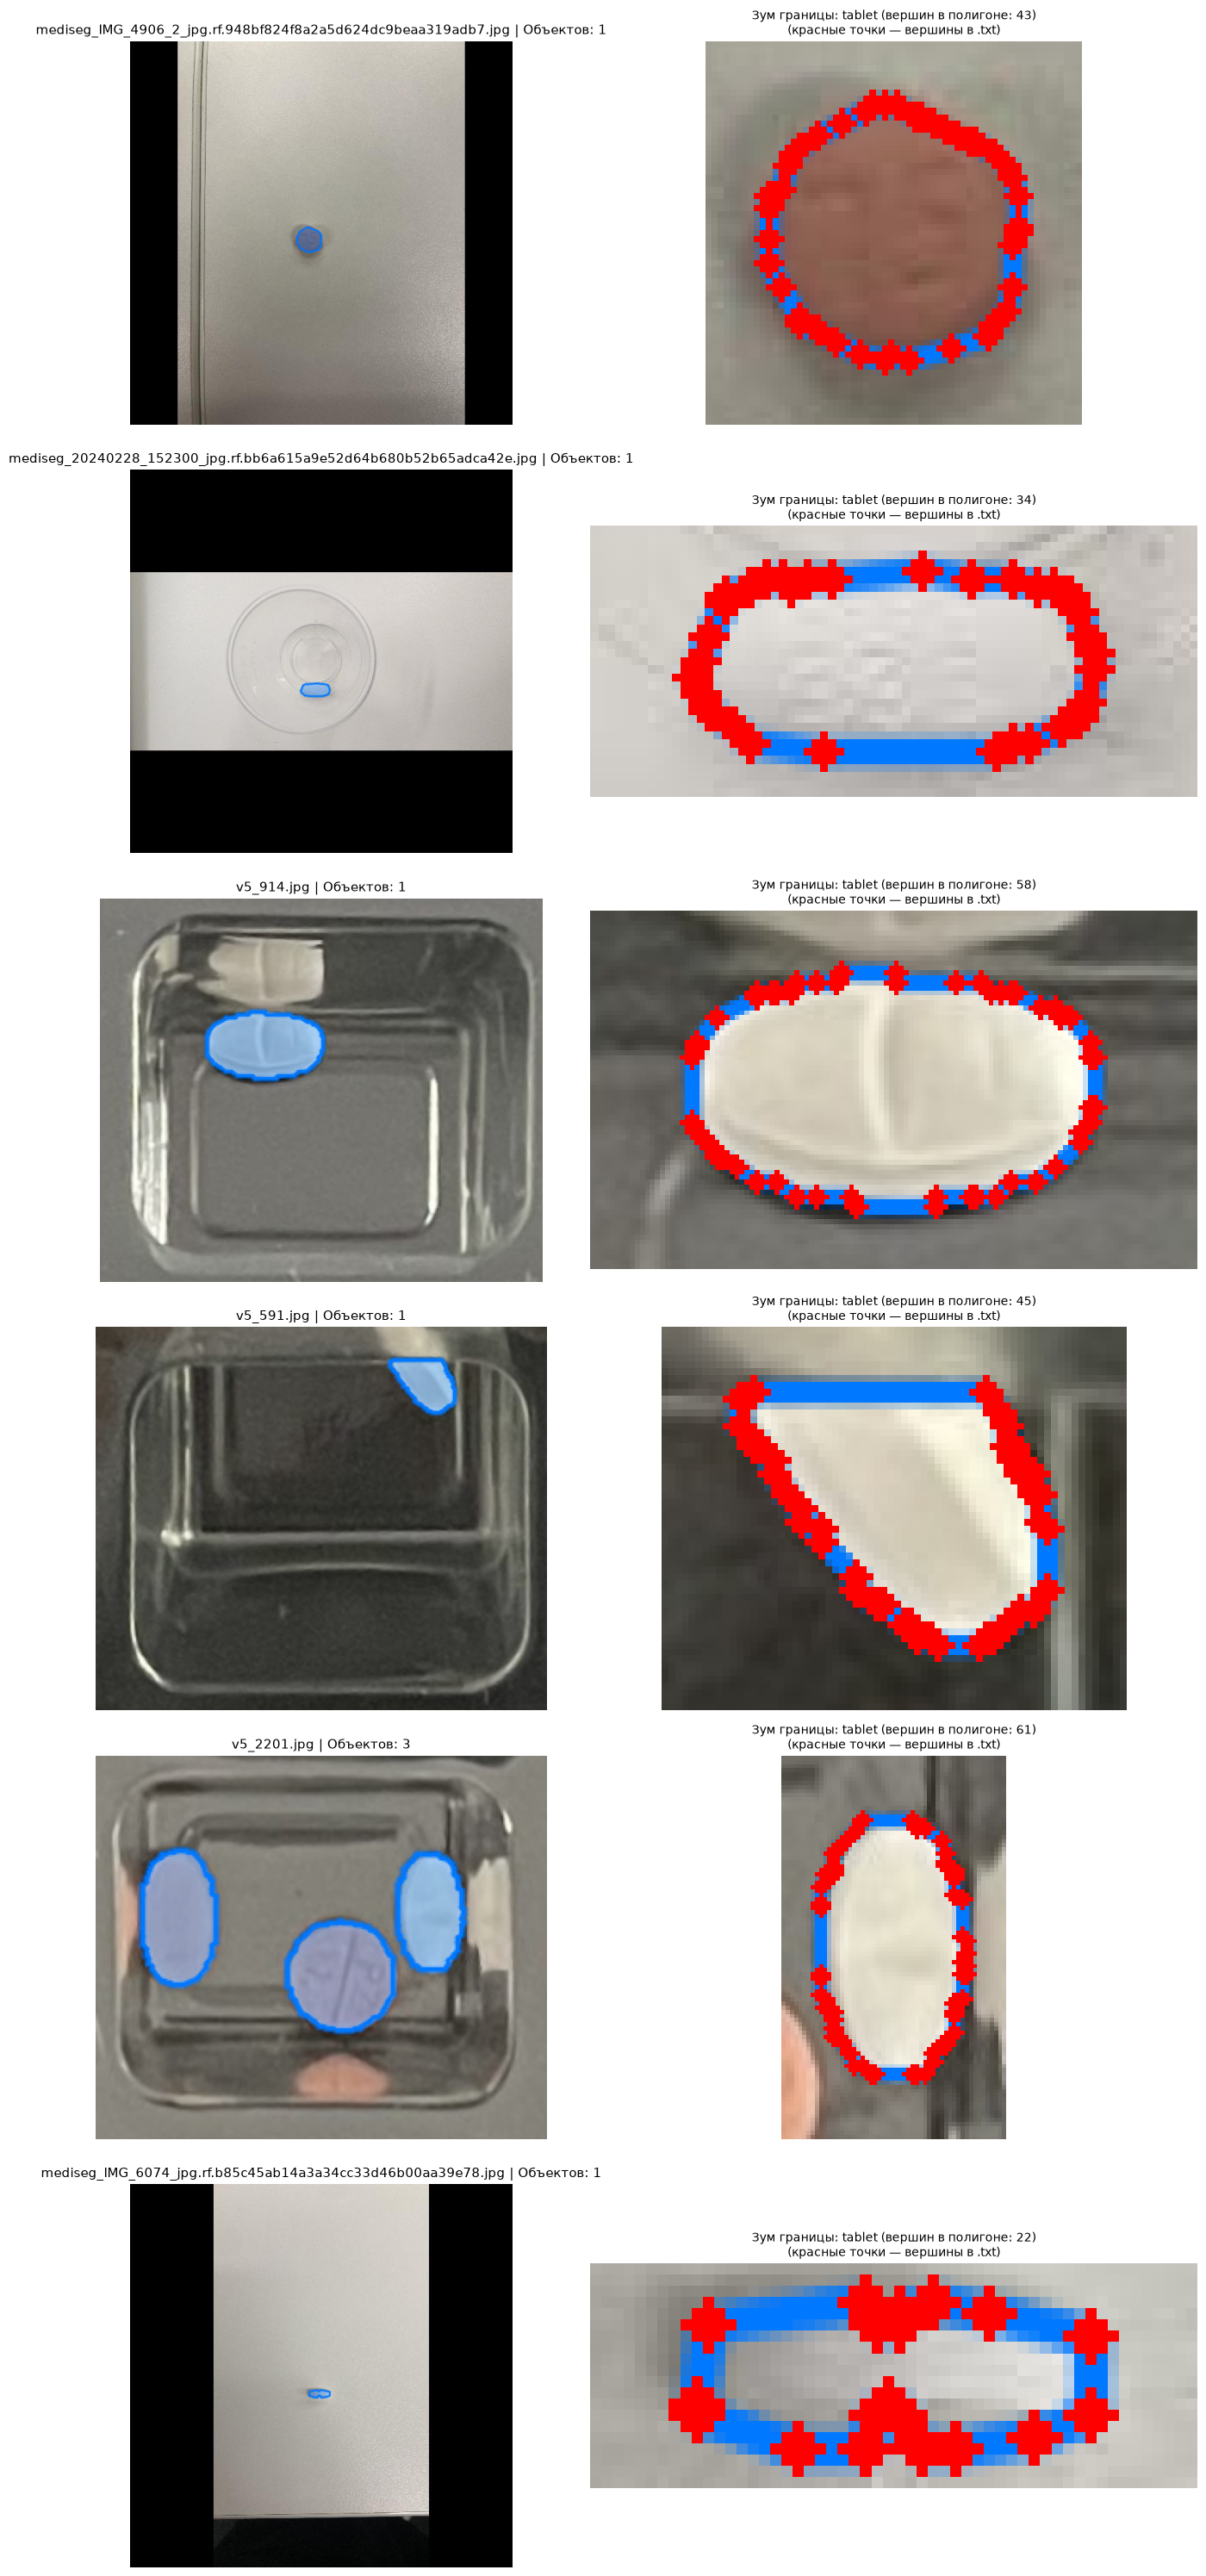

In [1]:
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Настройка путей к dataset_v6_seg
DATASET_DIR = Path(r"D:\Tabmed\Datasets\dataset_v6_seg")
IMAGES_DIR = DATASET_DIR / "images" / "train"
LABELS_DIR = DATASET_DIR / "labels" / "train"

# Если папка train пуста, проверяем общую структуру
if not IMAGES_DIR.exists():
    IMAGES_DIR = DATASET_DIR / "images"
    LABELS_DIR = DATASET_DIR / "labels"

# 2. Поиск файлов с разметкой
all_labels = list(LABELS_DIR.rglob("*.txt"))
if not all_labels:
    raise FileNotFoundError(f"Файлы разметки не найдены в: {LABELS_DIR}")

# Фильтруем только те лейблы, у которых есть соответствующее изображение
valid_pairs = []
valid_exts = [".jpg", ".png", ".jpeg"]
for lbl_p in all_labels:
    img_candidates = [
        IMAGES_DIR / lbl_p.parent.relative_to(LABELS_DIR) / f"{lbl_p.stem}{ext}"
        for ext in valid_exts
    ]
    img_p = next((p for p in img_candidates if p.exists()), None)
    if img_p:
        valid_pairs.append((img_p, lbl_p))

print(f"Всего доступно размеченных кадров: {len(valid_pairs)}")

# 3. Случайная выборка 6 файлов
random.seed(42)
samples = random.sample(valid_pairs, min(6, len(valid_pairs)))

# Схема классов и цветов (BGR для OpenCV): 0: capsule (зеленый), 1: tablet (синий)
CLASS_INFO = {
    0: {"name": "capsule", "color": (0, 255, 0)},
    1: {"name": "tablet", "color": (255, 120, 0)},
}

# 4. Отрисовка галереи: Полный кадр | Увеличенный фрагмент контура
fig, axes = plt.subplots(len(samples), 2, figsize=(14, 5 * len(samples)))
if len(samples) == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, (img_p, lbl_p) in enumerate(samples):
    img = cv2.imread(str(img_p))
    if img is None:
        continue
    h, w = img.shape[:2]

    overlay = img.copy()
    first_crop = None
    first_crop_title = ""
    detected_objects = 0

    with open(lbl_p, "r", encoding="utf-8") as f:
        lines = [line.strip().split() for line in f if line.strip()]

    for parts in lines:
        if len(parts) < 7:  # class + минимум 3 точки (x, y)
            continue

        cls_id = int(parts[0])
        coords = np.array(list(map(float, parts[1:])), dtype=np.float32).reshape(-1, 2)
        
        # Денормализация в пиксельные координаты
        coords[:, 0] *= w
        coords[:, 1] *= h
        poly = coords.astype(np.int32)

        info = CLASS_INFO.get(cls_id, {"name": f"id_{cls_id}", "color": (0, 255, 255)})
        color = info["color"]

        # Полупрозрачная заливка полигона и четкая линия контура
        cv2.fillPoly(overlay, [poly], color)
        cv2.polylines(img, [poly], isClosed=True, color=color, thickness=2, lineType=cv2.LINE_AA)

        # Сохраняем первый объект для детального зума контура
        if first_crop is None:
            x, y, bw, bh = cv2.boundingRect(poly)
            pad_x, pad_y = int(bw * 0.25), int(bh * 0.25)
            x1 = max(0, x - pad_x)
            y1 = max(0, y - pad_y)
            x2 = min(w, x + bw + pad_x)
            y2 = min(h, y + bh + pad_y)

            # Вырезаем фрагмент с уже нарисованной линией
            crop_bgr = img[y1:y2, x1:x2].copy()
            # Рисуем узловые вершины полигона красными точками, чтобы видеть изломы
            for pt in poly:
                px, py = pt[0] - x1, pt[1] - y1
                if 0 <= px < crop_bgr.shape[1] and 0 <= py < crop_bgr.shape[0]:
                    cv2.circle(crop_bgr, (px, py), 2, (0, 0, 255), -1)

            first_crop = crop_bgr
            first_crop_title = f"{info['name']} (вершин в полигоне: {len(poly)})"

        detected_objects += 1

    # Наложение прозрачной маски на базовое изображение
    viz_full = cv2.addWeighted(overlay, 0.35, img, 0.65, 0)
    viz_full_rgb = cv2.cvtColor(viz_full, cv2.COLOR_BGR2RGB)

    # Колонка 1: Общий вид
    axes[idx, 0].imshow(viz_full_rgb)
    axes[idx, 0].set_title(f"{img_p.name} | Объектов: {detected_objects}", fontsize=11)
    axes[idx, 0].axis("off")

    # Колонка 2: Крупный зум контура с красными вершинами
    if first_crop is not None and first_crop.size > 0:
        crop_rgb = cv2.cvtColor(first_crop, cv2.COLOR_BGR2RGB)
        axes[idx, 1].imshow(crop_rgb)
        axes[idx, 1].set_title(f"Зум границы: {first_crop_title}\n(красные точки — вершины в .txt)", fontsize=10)
    else:
        axes[idx, 1].text(0.5, 0.5, "Полигоны не найдены", ha="center")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

# Выыод датасета с рамками сегментации

In [4]:
from pathlib import Path
import cv2
import numpy as np
from tqdm import tqdm

DATASET_DIR = Path(r"D:\Tabmed\Datasets\dataset_v6_seg")
IMAGES_DIR = DATASET_DIR / "images" / "train"
LABELS_DIR = DATASET_DIR / "labels" / "train"
OUT_DIR = Path(r"D:\Tabmed\inspect_masks")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 0: capsule (зеленый BGR), 1: tablet (синий BGR)
COLORS = {
    0: (0, 255, 0),
    1: (255, 120, 0)
}

label_files = list(LABELS_DIR.glob("*.txt"))
print(f"Найдено аннотаций: {len(label_files)}. Начинаем экспорт...")

# Если нужно посмотреть не все, а первые N — укажите срез, например label_files[:100]
for lbl_p in tqdm(label_files):
    # Поиск соответствующего изображения
    img_candidates = [IMAGES_DIR / f"{lbl_p.stem}{ext}" for ext in [".jpg", ".png", ".jpeg"]]
    img_p = next((p for p in img_candidates if p.exists()), None)
    if not img_p:
        continue

    img = cv2.imread(str(img_p))
    if img is None:
        continue
    h, w = img.shape[:2]

    overlay = img.copy()

    with open(lbl_p, "r", encoding="utf-8") as f:
        lines = [line.strip().split() for line in f if line.strip()]

    for parts in lines:
        if len(parts) < 7:
            continue
        cls_id = int(parts[0])
        coords = np.array(list(map(float, parts[1:])), dtype=np.float32).reshape(-1, 2)
        coords[:, 0] *= w
        coords[:, 1] *= h
        poly = coords.astype(np.int32)

        col = COLORS.get(cls_id, (0, 255, 255))
        cv2.fillPoly(overlay, [poly], col)
        cv2.polylines(img, [poly], isClosed=True, color=col, thickness=2, lineType=cv2.LINE_AA)

    res = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)
    cv2.imwrite(str(OUT_DIR / f"viz_{img_p.stem}.jpg"), res)

print(f"Готово! Все изображения сохранены в папку:\n{OUT_DIR.resolve()}")

Найдено аннотаций: 568. Начинаем экспорт...


100%|██████████| 568/568 [00:09<00:00, 57.71it/s] 

Готово! Все изображения сохранены в папку:
D:\Tabmed\inspect_masks


# Сглаживание контуров

In [5]:
import shutil
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# 1. Определение путей (автоопределение расположения)
POSSIBLE_DIRS = [
    Path(r"D:\Tabmed\Datasets\dataset_v6_seg"),
    Path(r"D:\Tabmed\dataset_v6_seg"),
]
SRC_DIR = next((d for d in POSSIBLE_DIRS if d.exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("Папка с исходным датасетом v6 не найдена!")

DST_DIR = SRC_DIR.parent / "dataset_v6_seg_clean"
print(f"Источник: {SRC_DIR}")
print(f"Целевая папка для чистых данных: {DST_DIR}")

# 2. Пороговые параметры фильтрации
MIN_AREA_PX = 150  # Исключаем микро-артефакты размером меньше 150 пикселей
MIN_SOLIDITY = 0.72  # Капсулы и таблетки выпуклые; рваные блики имеют низкую солидность
SMOOTH_EPSILON_RATIO = 0.0035  # Сила сглаживания дуги (чем выше, тем круглее контур)


def smooth_and_filter_polygon(coords_norm, w, h):
    """Сглаживает зубчатые контуры через локальный ROI и отсекает геометрический брак."""
    coords_px = np.copy(coords_norm)
    coords_px[:, 0] *= w
    coords_px[:, 1] *= h
    poly = coords_px.astype(np.int32)

    # Быстрая проверка габаритов
    x, y, bw, bh = cv2.boundingRect(poly)
    if bw < 8 or bh < 8 or (bw * bh) < MIN_AREA_PX:
        return None

    # Вырезаем локальный бинарный ROI с запасом в 5 пикселей
    pad = 5
    roi_x1 = max(0, x - pad)
    roi_y1 = max(0, y - pad)
    roi_x2 = min(w, x + bw + pad)
    roi_y2 = min(h, y + bh + pad)

    roi_w = roi_x2 - roi_x1
    roi_h = roi_y2 - roi_y1
    if roi_w <= 0 or roi_h <= 0:
        return None

    mask_roi = np.zeros((roi_h, roi_w), dtype=np.uint8)
    poly_shifted = poly - np.array([roi_x1, roi_y1])
    cv2.fillPoly(mask_roi, [poly_shifted], 255)

    # Морфологическое замыкание эллиптическим ядром (убирает ступеньки и зазубрины)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask_closed = cv2.morphologyEx(mask_roi, cv2.MORPH_CLOSE, kernel)
    mask_blurred = cv2.GaussianBlur(mask_closed, (5, 5), 0)
    _, mask_clean = cv2.threshold(mask_blurred, 127, 255, cv2.THRESH_BINARY)

    # Извлечение чистого контура
    contours, _ = cv2.findContours(
        mask_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return None

    cnt = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    if area < MIN_AREA_PX:
        return None

    # Проверка выпуклости (Solidity = Площадь / Площадь выпуклой оболочки)
    hull = cv2.convexHull(cnt)
    hull_area = cv2.contourArea(hull)
    if hull_area == 0:
        return None
    solidity = float(area) / hull_area
    if solidity < MIN_SOLIDITY:
        return None

    # Аппроксимация полигона без потери эллиптической формы
    peri = cv2.arcLength(cnt, True)
    approx = cv2.approxPolyDP(cnt, SMOOTH_EPSILON_RATIO * peri, True)

    if len(approx) < 6:
        # Если точек слишком мало для кривой, берем выпуклую оболочку
        approx = cv2.approxPolyDP(hull, 0.002 * cv2.arcLength(hull, True), True)
        if len(approx) < 4:
            return None

    # Возврат в абсолютные координаты изображения
    clean_pts = approx.reshape(-1, 2) + np.array([roi_x1, roi_y1])

    # Нормализация в диапазон [0, 1]
    clean_norm = clean_pts.astype(np.float32)
    clean_norm[:, 0] = np.clip(clean_norm[:, 0] / w, 0.0, 1.0)
    clean_norm[:, 1] = np.clip(clean_norm[:, 1] / h, 0.0, 1.0)

    return clean_norm


# 3. Обработка всех сплитов (train / val)
stats = {"total": 0, "kept": 0, "dropped": 0, "files_removed": 0}

for split in ["train", "val"]:
    src_img_dir = SRC_DIR / "images" / split
    src_lbl_dir = SRC_DIR / "labels" / split

    if not src_img_dir.exists():
        continue

    dst_img_dir = DST_DIR / "images" / split
    dst_lbl_dir = DST_DIR / "labels" / split
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)

    lbl_files = list(src_lbl_dir.glob("*.txt"))
    print(f"\nОбработка сплита '{split}' ({len(lbl_files)} аннотаций)...")

    for lbl_p in tqdm(lbl_files):
        # Поиск картинки
        img_p = next(
            (
                src_img_dir / f"{lbl_p.stem}{ext}"
                for ext in [".jpg", ".png", ".jpeg"]
                if (src_img_dir / f"{lbl_p.stem}{ext}").exists()
            ),
            None,
        )
        if not img_p:
            continue

        img = cv2.imread(str(img_p))
        if img is None:
            continue
        h, w = img.shape[:2]

        with open(lbl_p, "r", encoding="utf-8") as f:
            lines = [l.strip().split() for l in f if l.strip()]

        cleaned_lines = []
        for parts in lines:
            if len(parts) < 7:
                continue
            stats["total"] += 1
            cls_id = parts[0]
            pts = np.array(list(map(float, parts[1:])), dtype=np.float32).reshape(
                -1, 2
            )

            smoothed = smooth_and_filter_polygon(pts, w, h)
            if smoothed is not None:
                flat_coords = " ".join([f"{x:.6f} {y:.6f}" for x, y in smoothed])
                cleaned_lines.append(f"{cls_id} {flat_coords}")
                stats["kept"] += 1
            else:
                stats["dropped"] += 1

        # Сохраняем кадр только если на нем остался хотя бы один валидный объект
        if cleaned_lines:
            shutil.copy2(img_p, dst_img_dir / img_p.name)
            with open(
                dst_lbl_dir / lbl_p.name, "w", encoding="utf-8"
            ) as f_out:
                f_out.write("\n".join(cleaned_lines) + "\n")
        else:
            stats["files_removed"] += 1

# Генерация data.yaml для нового датасета
yaml_content = f"""path: {DST_DIR.as_posix()}
train: images/train
val: images/val

names:
  0: capsule
  1: tablet
"""
with open(DST_DIR / "data.yaml", "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("\n" + "=" * 50)
print(f"Всего полигонов обработано: {stats['total']}")
print(f"Успешно сглажено и оставлено: {stats['kept']}")
print(f"Отсеяно брака и рваных контуров: {stats['dropped']}")
print(f"Пустых кадров исключено: {stats['files_removed']}")
print(f"Новый чистый датасет готов в:\n{DST_DIR}")
print("=" * 50)

Источник: D:\Tabmed\Datasets\dataset_v6_seg
Целевая папка для чистых данных: D:\Tabmed\Datasets\dataset_v6_seg_clean

Обработка сплита 'train' (568 аннотаций)...


100%|██████████| 568/568 [00:06<00:00, 93.96it/s] 



Обработка сплита 'val' (143 аннотаций)...


100%|██████████| 143/143 [00:02<00:00, 68.17it/s]


Всего полигонов обработано: 7212
Успешно сглажено и оставлено: 7147
Отсеяно брака и рваных контуров: 65
Пустых кадров исключено: 0
Новый чистый датасет готов в:
D:\Tabmed\Datasets\dataset_v6_seg_clean


# Сравнение датасетов до и после

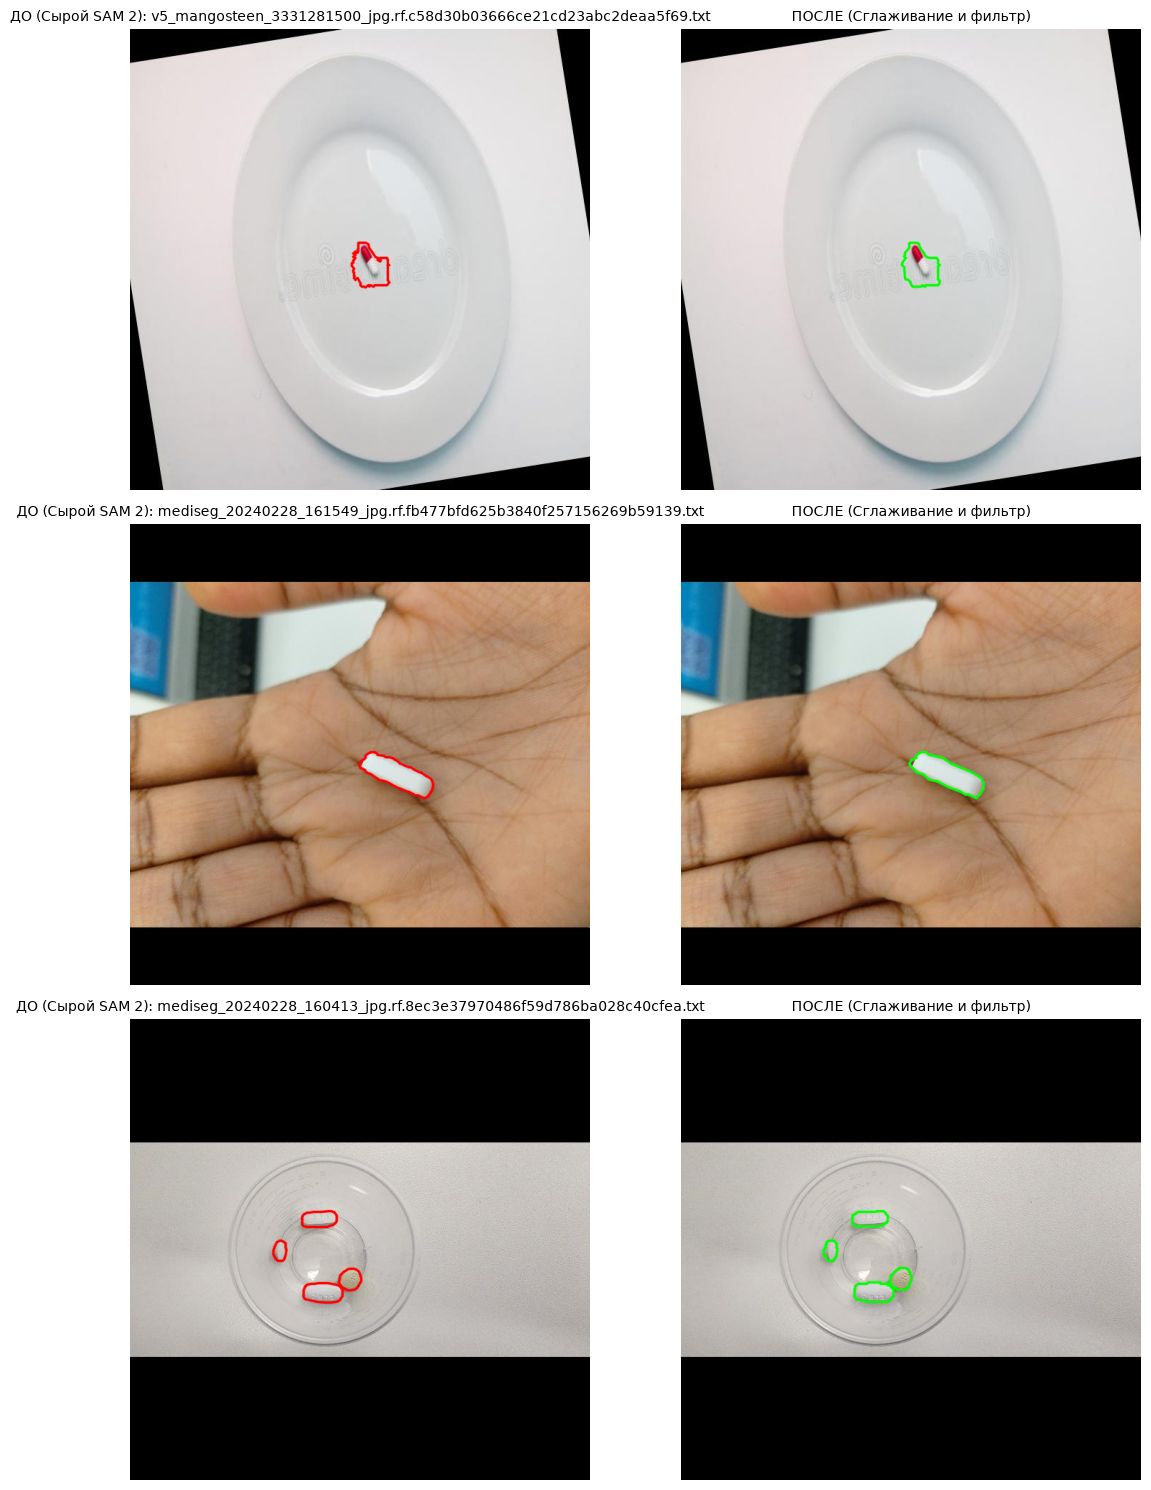

In [7]:
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Берем 3 случайных кадра из обработанных
clean_labels = list((DST_DIR / "labels" / "train").glob("*.txt"))
sample_labels = random.sample(clean_labels, min(3, len(clean_labels)))

fig, axes = plt.subplots(len(sample_labels), 2, figsize=(12, 5 * len(sample_labels)))
if len(sample_labels) == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, new_lbl in enumerate(sample_labels):
    old_lbl = SRC_DIR / "labels" / "train" / new_lbl.name
    img_candidates = [
        DST_DIR / "images" / "train" / f"{new_lbl.stem}{ext}"
        for ext in [".jpg", ".png", ".jpeg"]
    ]
    img_p = next((p for p in img_candidates if p.exists()), None)
    if not img_p:
        continue

    img_raw = cv2.imread(str(img_p))
    h, w = img_raw.shape[:2]

    img_before = img_raw.copy()
    img_after = img_raw.copy()

    # Отрисовка ДО (красный контур)
    if old_lbl.exists():
        with open(old_lbl, "r") as f:
            for line in f:
                p = line.strip().split()
                if len(p) >= 7:
                    pts = (
                        np.array(list(map(float, p[1:])), dtype=np.float32).reshape(
                            -1, 2
                        )
                        * [w, h]
                    ).astype(np.int32)
                    cv2.polylines(img_before, [pts], True, (0, 0, 255), 2, cv2.LINE_AA)

    # Отрисовка ПОСЛЕ (зеленый контур)
    with open(new_lbl, "r") as f:
        for line in f:
            p = line.strip().split()
            if len(p) >= 7:
                pts = (
                    np.array(list(map(float, p[1:])), dtype=np.float32).reshape(-1, 2)
                    * [w, h]
                ).astype(np.int32)
                cv2.polylines(img_after, [pts], True, (0, 255, 0), 2, cv2.LINE_AA)

    axes[idx, 0].imshow(cv2.cvtColor(img_before, cv2.COLOR_BGR2RGB))
    axes[idx, 0].set_title(f"ДО (Сырой SAM 2): {new_lbl.name}", fontsize=10)
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(cv2.cvtColor(img_after, cv2.COLOR_BGR2RGB))
    axes[idx, 1].set_title("ПОСЛЕ (Сглаживание и фильтр)", fontsize=10)
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

# Создание нового датасета dataset_v7_seg_up без бракованных фоток в низком качестве

In [9]:
import shutil
from pathlib import Path
import cv2
import numpy as np
from tqdm import tqdm

# 1. Поиск исходного dataset_v6_seg
POSSIBLE_DIRS = [
    Path(r"D:\Tabmed\Datasets\dataset_v6_seg"),
    Path(r"D:\Tabmed\dataset_v6_seg")
]
SRC_DIR = next((d for d in POSSIBLE_DIRS if d.exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("Папка dataset_v6_seg не найдена!")

DST_DIR = SRC_DIR.parent / "dataset_v7_seg_up"
print(f"Источник: {SRC_DIR}")
print(f"Новый датасет: {DST_DIR}")

# 2. Параметры первичного отбора
MIN_IMG_DIM = 650     # Отсекаем снимки 600x600 и ниже с битой разметкой блистеров
MIN_OBJ_AREA_PX = 180 # Отсекаем микро-пятна

def smooth_convex_polygon(coords_norm, w, h):
    """Превращает рваный контур в строгий выпуклый эллипс/капсулу через Convex Hull."""
    pts_px = (coords_norm * [w, h]).astype(np.int32)
    
    # Расчет выпуклой оболочки (срезает все внутренние зубья и ступени)
    hull = cv2.convexHull(pts_px)
    area = cv2.contourArea(hull)
    if area < MIN_OBJ_AREA_PX:
        return None
    
    # Аппроксимация дуги: оставляет от 12 до 24 опорных точек для идеальной дуги YOLO
    peri = cv2.arcLength(hull, True)
    approx = cv2.approxPolyDP(hull, 0.0035 * peri, True)
    if len(approx) < 4:
        return None
        
    pts_clean = approx.reshape(-1, 2).astype(np.float32)
    pts_clean[:, 0] = np.clip(pts_clean[:, 0] / w, 0.0, 1.0)
    pts_clean[:, 1] = np.clip(pts_clean[:, 1] / h, 0.0, 1.0)
    return pts_clean

# 3. Перенос и обработка
stats = {"copied_imgs": 0, "skipped_lowres": 0, "kept_poly": 0, "dropped_poly": 0}

for split in ["train", "val"]:
    src_img_dir = SRC_DIR / "images" / split
    src_lbl_dir = SRC_DIR / "labels" / split
    if not src_img_dir.exists():
        continue

    dst_img_dir = DST_DIR / "images" / split
    dst_lbl_dir = DST_DIR / "labels" / split
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)

    lbl_files = list(src_lbl_dir.glob("*.txt"))
    print(f"\nОбработка сплита '{split}'...")

    for lbl_p in tqdm(lbl_files):
        img_p = next((src_img_dir / f"{lbl_p.stem}{ext}" for ext in [".jpg", ".png", ".jpeg"] 
                      if (src_img_dir / f"{lbl_p.stem}{ext}").exists()), None)
        if not img_p:
            continue

        img = cv2.imread(str(img_p))
        if img is None:
            continue
        h, w = img.shape[:2]

        # Фильтр по низкому разрешению
        if min(h, w) < MIN_IMG_DIM:
            stats["skipped_lowres"] += 1
            continue

        with open(lbl_p, "r", encoding="utf-8") as f:
            lines = [l.strip().split() for l in f if l.strip()]

        clean_lines = []
        for parts in lines:
            if len(parts) < 7:
                continue
            cls_id = parts[0]
            pts = np.array(list(map(float, parts[1:])), dtype=np.float32).reshape(-1, 2)
            
            hull_pts = smooth_convex_polygon(pts, w, h)
            if hull_pts is not None:
                flat_str = " ".join([f"{x:.6f} {y:.6f}" for x, y in hull_pts])
                clean_lines.append(f"{cls_id} {flat_str}")
                stats["kept_poly"] += 1
            else:
                stats["dropped_poly"] += 1

        if clean_lines:
            shutil.copy2(img_p, dst_img_dir / img_p.name)
            with open(dst_lbl_dir / lbl_p.name, "w", encoding="utf-8") as f_out:
                f_out.write("\n".join(clean_lines) + "\n")
            stats["copied_imgs"] += 1

# Конфиг data.yaml
yaml_content = f"""path: {DST_DIR.as_posix()}
train: images/train
val: images/val

names:
  0: capsule
  1: tablet
"""
with open(DST_DIR / "data.yaml", "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("\n" + "="*50)
print(f"Кадров перенесено в dataset_v7_seg_up: {stats['copied_imgs']}")
print(f"Пропущено низкокачественных (шакальных) кадров: {stats['skipped_lowres']}")
print(f"Полигонов выровнено: {stats['kept_poly']}")
print(f"Папка с новым датасетом: {DST_DIR}")
print("="*50)

Источник: D:\Tabmed\Datasets\dataset_v6_seg
Новый датасет: D:\Tabmed\Datasets\dataset_v7_seg_up

Обработка сплита 'train'...


100%|██████████| 568/568 [00:03<00:00, 143.59it/s]



Обработка сплита 'val'...


100%|██████████| 143/143 [00:00<00:00, 147.14it/s]


Кадров перенесено в dataset_v7_seg_up: 102
Пропущено низкокачественных (шакальных) кадров: 609
Полигонов выровнено: 1199
Папка с новым датасетом: D:\Tabmed\Datasets\dataset_v7_seg_up


# Просмотр фоток с контурами

In [10]:
from pathlib import Path
import cv2
import numpy as np
from tqdm import tqdm

DATASET_DIR = Path(r"D:\Tabmed\Datasets\dataset_v7_seg_up")
if not DATASET_DIR.exists():
    DATASET_DIR = Path(r"D:\Tabmed\dataset_v7_seg_up")

INSPECT_DIR = Path(r"D:\Tabmed\inspect_v7")
INSPECT_DIR.mkdir(parents=True, exist_ok=True)

# Цвета для классов: 0 — capsule (зеленый), 1 — tablet (синий)
COLORS = {0: (0, 255, 0), 1: (255, 120, 0)}

img_files = list((DATASET_DIR / "images" / "train").glob("*.*"))
print(f"Генерация превью для {len(img_files)} кадров...")

for img_p in tqdm(img_files):
    lbl_p = DATASET_DIR / "labels" / "train" / f"{img_p.stem}.txt"
    if not lbl_p.exists():
        continue

    img = cv2.imread(str(img_p))
    if img is None:
        continue
    h, w = img.shape[:2]
    overlay = img.copy()

    with open(lbl_p, "r", encoding="utf-8") as f:
        lines = [line.strip().split() for line in f if line.strip()]

    for parts in lines:
        if len(parts) < 7:
            continue
        cls_id = int(parts[0])
        coords = np.array(list(map(float, parts[1:])), dtype=np.float32).reshape(-1, 2)
        poly = (coords * [w, h]).astype(np.int32)

        col = COLORS.get(cls_id, (0, 255, 255))
        cv2.fillPoly(overlay, [poly], col)
        cv2.polylines(img, [poly], isClosed=True, color=col, thickness=2, lineType=cv2.LINE_AA)

    # Наложение маски и сохранение в папку инспекции
    res = cv2.addWeighted(overlay, 0.35, img, 0.65, 0)
    cv2.imwrite(str(INSPECT_DIR / img_p.name), res)

print(f"\nГотово! Откройте папку для просмотра:\n{INSPECT_DIR.resolve()}")

Генерация превью для 85 кадров...


100%|██████████| 85/85 [00:06<00:00, 14.05it/s]


Готово! Откройте папку для просмотра:
D:\Tabmed\inspect_v7


# Перенос старой разметки и деление датасета

In [11]:
import random
import shutil
from pathlib import Path
import yaml

DATASET_DIR = Path(r"D:\Tabmed\Datasets\dataset_v7_seg_up")
if not DATASET_DIR.exists():
    DATASET_DIR = Path(r"D:\Tabmed\dataset_v7_seg_up")

INSPECT_DIR = Path(r"D:\Tabmed\inspect_v7")

# 1. Синхронизация: оставляем только те файлы, что выжили в inspect_v7
kept_stems = {p.stem for p in INSPECT_DIR.glob("*.*")}

# Собираем все реальные пары (картинка + txt)
all_pairs = []
for split in ["train", "val"]:
    img_dir = DATASET_DIR / "images" / split
    lbl_dir = DATASET_DIR / "labels" / split
    if not img_dir.exists():
        continue
    for img_p in list(img_dir.glob("*.*")):
        if img_p.stem in kept_stems:
            lbl_p = lbl_dir / f"{img_p.stem}.txt"
            if lbl_p.exists():
                all_pairs.append((img_p, lbl_p))
        else:
            # Удаляем отбракованные
            img_p.unlink()
            lbl_p = lbl_dir / f"{img_p.stem}.txt"
            if lbl_p.exists():
                lbl_p.unlink()

print(f"Всего чистых размеченных пар для обучения: {len(all_pairs)}")

# 2. Перераспределение на train (80%) и val (20%)
random.seed(42)
random.shuffle(all_pairs)

split_idx = int(len(all_pairs) * 0.8)
train_pairs = all_pairs[:split_idx]
val_pairs = all_pairs[split_idx:]

# Очистка и пересоздание целевых директорий
for split, pairs in [("train", train_pairs), ("val", val_pairs)]:
    target_img_dir = DATASET_DIR / "images" / split
    target_lbl_dir = DATASET_DIR / "labels" / split
    
    # Создаем временную структуру, чтобы безопасно переместить файлы
    temp_img_dir = DATASET_DIR / "images" / f"temp_{split}"
    temp_lbl_dir = DATASET_DIR / "labels" / f"temp_{split}"
    temp_img_dir.mkdir(parents=True, exist_ok=True)
    temp_lbl_dir.mkdir(parents=True, exist_ok=True)

    for img_p, lbl_p in pairs:
        shutil.move(str(img_p), str(temp_img_dir / img_p.name))
        shutil.move(str(lbl_p), str(temp_lbl_dir / lbl_p.name))

# Заменяем старые папки новыми
for split in ["train", "val"]:
    old_img_dir = DATASET_DIR / "images" / split
    old_lbl_dir = DATASET_DIR / "labels" / split
    temp_img_dir = DATASET_DIR / "images" / f"temp_{split}"
    temp_lbl_dir = DATASET_DIR / "labels" / f"temp_{split}"

    if old_img_dir.exists():
        shutil.rmtree(old_img_dir)
    if old_lbl_dir.exists():
        shutil.rmtree(old_lbl_dir)

    temp_img_dir.rename(old_img_dir)
    temp_lbl_dir.rename(old_lbl_dir)

# 3. Фиксация data.yaml
yaml_cfg = {
    "path": DATASET_DIR.as_posix(),
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "capsule",
        1: "tablet"
    }
}
with open(DATASET_DIR / "data.yaml", "w", encoding="utf-8") as f:
    yaml.dump(yaml_cfg, f, default_flow_style=False)

print(f"Готово: Train: {len(train_pairs)} кадров | Val: {len(val_pairs)} кадров")
print(f"Конфиг сохранен в: {DATASET_DIR / 'data.yaml'}")

Всего чистых размеченных пар для обучения: 73
Готово: Train: 58 кадров | Val: 15 кадров
Конфиг сохранен в: D:\Tabmed\Datasets\dataset_v7_seg_up\data.yaml


# Создание бекапа модели

In [12]:
import shutil
from pathlib import Path

BASE_DIR = Path(r"D:\Tabmed\Tabmed_ml")
CURRENT_BEST = BASE_DIR / "best.pt"
BACKUP_PATH = BASE_DIR / "best_v6_seg_backup.pt"

if CURRENT_BEST.is_file():
    shutil.copy2(CURRENT_BEST, BACKUP_PATH)
    print(f"Текущая модель надежно сохранена в: {BACKUP_PATH.name}")
else:
    print("Файл best.pt в корне не найден!")

Текущая модель надежно сохранена в: best_v6_seg_backup.pt


# Обучение модели

In [13]:
from pathlib import Path
from ultralytics import YOLO

# Пути
DATASET_DIR = Path(r"D:\Tabmed\Datasets\dataset_v7_seg_up")
if not DATASET_DIR.exists():
    DATASET_DIR = Path(r"D:\Tabmed\dataset_v7_seg_up")

yaml_path = DATASET_DIR / "data.yaml"

# 1. Загружаем локальную базовую модель YOLO26-seg из корня проекта
model = YOLO("yolo26n-seg.pt")

# 2. Запуск обучения на чистом датасете v7
results = model.train(
    data=str(yaml_path),
    epochs=100,
    patience=25,
    imgsz=640,
    batch=16,
    device=0,  # RTX 4060 Ti
    workers=2,  # Стабильно для Windows
    project=r"D:\Tabmed\Tabmed_ml\runs\segment",
    name="tabmed_yolo26n_seg_clean",
    exist_ok=True,
    # Аугментации под компактный датасет
    degrees=180.0,
    fliplr=0.5,
    flipud=0.5,
    scale=0.5,
    mosaic=1.0,
    mixup=0.1,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,
    # Оптимизатор
    optimizer="auto",
    lr0=0.01,
    lrf=0.01,
    weight_decay=0.0005,
    save=True,
    val=True,
)

print("\nОбучение YOLO26-seg завершено!")
print(f"Лучшие веса сохранены в: {results.save_dir / 'weights' / 'best.pt'}")

New https://pypi.org/project/ultralytics/8.4.200 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.12.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tabmed\Datasets\dataset_v7_seg_up\data.yaml, degrees=180.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode

# Проверка

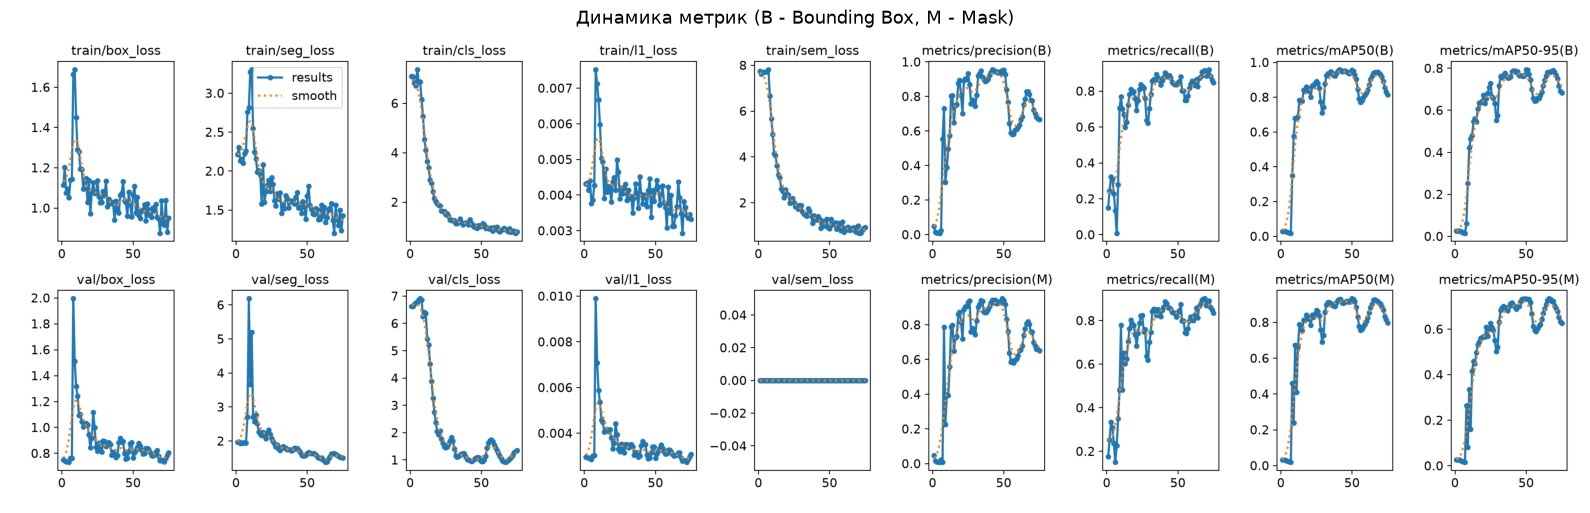

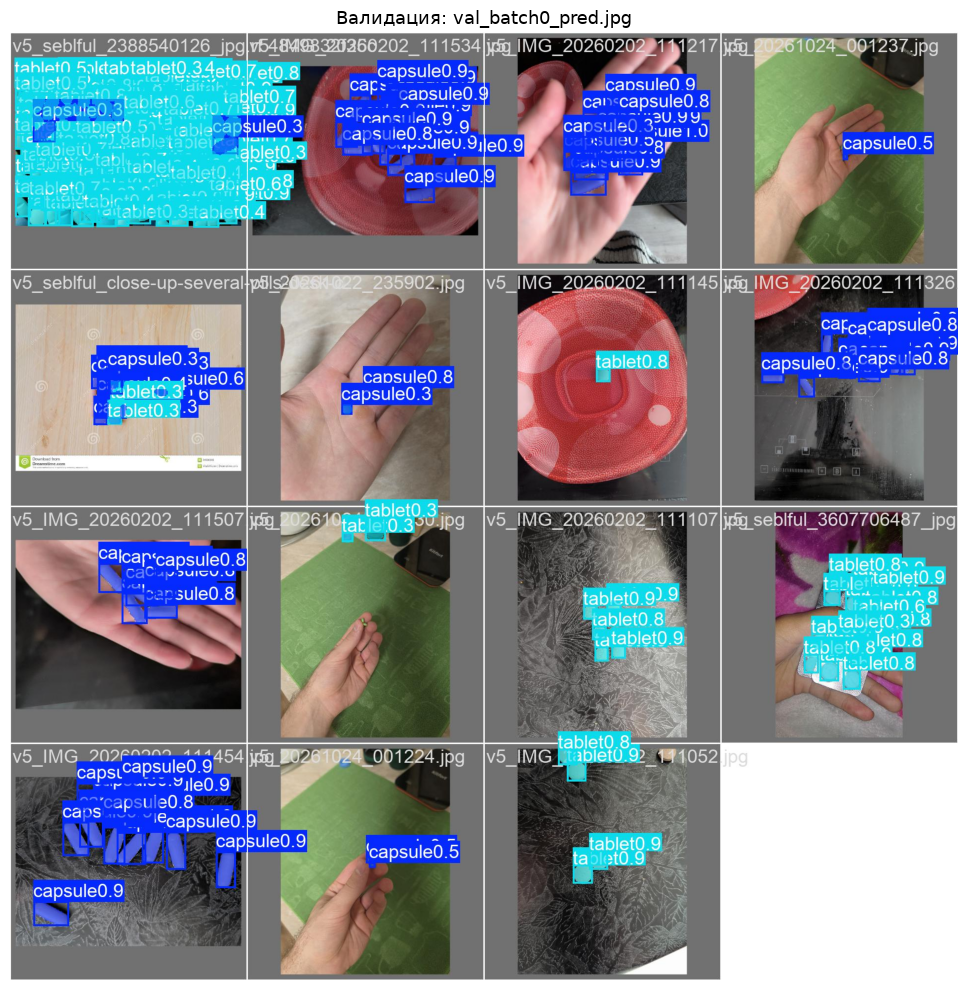

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

EXP_DIR = Path(r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_seg_clean")

# 1. Вывод графика результатов обучения (Losses, mAP50(B), mAP50(M))
results_png = EXP_DIR / "results.png"
if results_png.exists():
    img_res = cv2.imread(str(results_png))
    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(img_res, cv2.COLOR_BGR2RGB))
    plt.title("Динамика метрик (B - Bounding Box, M - Mask)", fontsize=13)
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"Файл {results_png} не найден.")

# 2. Отрисовка предсказаний на валидационном батче
val_preds = list(EXP_DIR.glob("val_batch*_pred.jpg"))
if val_preds:
    val_img = cv2.imread(str(val_preds[0]))
    plt.figure(figsize=(14, 10))
    plt.imshow(cv2.cvtColor(val_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Валидация: {val_preds[0].name}", fontsize=13)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

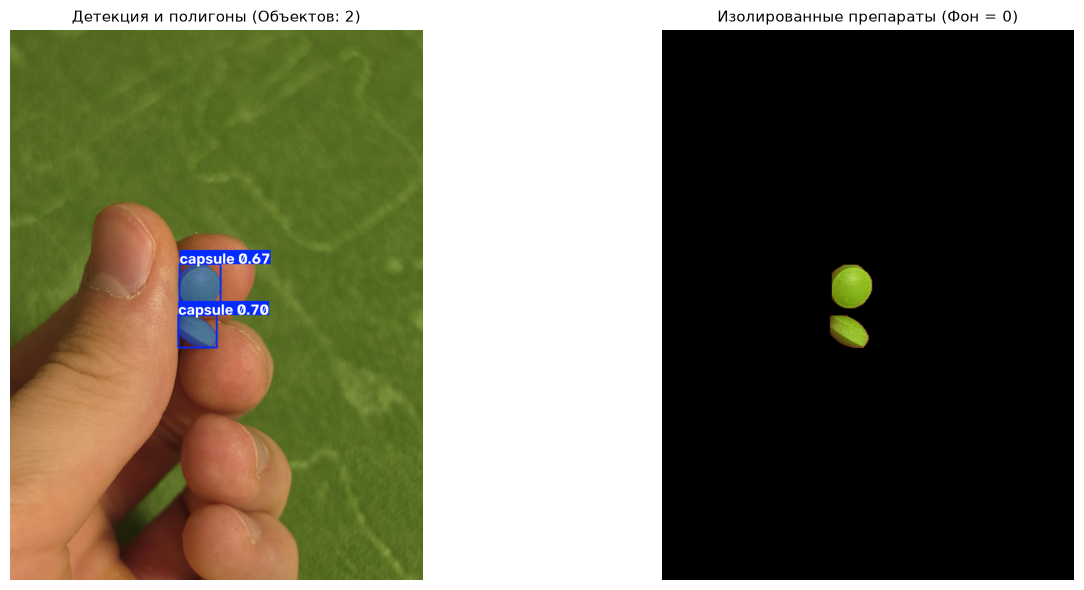

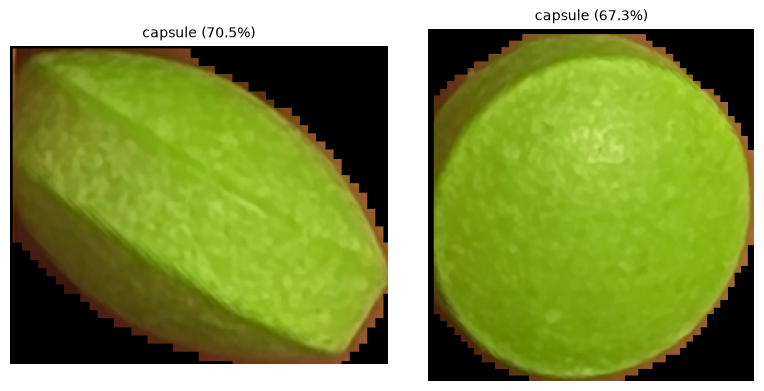

In [15]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Путь к обученным весам чистой версии v7
WEIGHTS_PATH = Path(r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_seg_clean\weights\best.pt")
TEST_IMG = Path(r"D:\Tabmed\Tabmed_ml\test.jpg")

if not WEIGHTS_PATH.exists():
    raise FileNotFoundError(f"Веса не найдены по пути: {WEIGHTS_PATH}")

model = YOLO(str(WEIGHTS_PATH))

# Инференс
results = model.predict(source=str(TEST_IMG), conf=0.35, verbose=False)
r = results[0]

orig_bgr = cv2.imread(str(TEST_IMG))
orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
h, w = orig_rgb.shape[:2]

isolated_rgb = np.zeros_like(orig_rgb)
detected_crops = []

if r.masks is not None:
    # Бинарные маски для каждого найденного объекта
    masks_arr = r.masks.data.cpu().numpy()
    
    # Сборка общей маски сцены
    combined_mask = np.any(masks_arr, axis=0).astype(np.uint8)
    combined_mask = cv2.resize(combined_mask, (w, h), interpolation=cv2.INTER_NEAREST)
    
    # Обнуление фона
    isolated_rgb = cv2.bitwise_and(orig_rgb, orig_rgb, mask=combined_mask)
    
    # Нарезка отдельных кропов для контроля края
    for idx, (box, m) in enumerate(zip(r.boxes, masks_arr)):
        cls_name = r.names[int(box.cls[0].item())]
        conf = float(box.conf[0].item())
        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
        
        # Индивидуальная маска объекта
        obj_mask = cv2.resize((m > 0.5).astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
        obj_isolated = cv2.bitwise_and(orig_rgb, orig_rgb, mask=obj_mask)
        crop = obj_isolated[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]
        
        detected_crops.append((crop, f"{cls_name} ({conf:.1%})"))

# Отрисовка сравнения
fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(r.plot()[:, :, ::-1])
ax1.set_title(f"Детекция и полигоны (Объектов: {len(r.boxes)})", fontsize=11)
ax1.axis("off")

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(isolated_rgb)
ax2.set_title("Изолированные препараты (Фон = 0)", fontsize=11)
ax2.axis("off")
plt.tight_layout()
plt.show()

# Отрисовка вырезанных фрагментов крупным планом
if detected_crops:
    fig, axes = plt.subplots(1, len(detected_crops), figsize=(4 * len(detected_crops), 4))
    if len(detected_crops) == 1:
        axes = [axes]
    for ax, (c, title) in zip(axes, detected_crops):
        ax.imshow(c)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()